        # Lesson 8.1 · The Artificial Neuron
        ### Neurons, perceptrons, layers, weights, biases and activation functions: from scratch in NumPy

        | | |
        |---|---|
        | ⏱️ **Time** | about 90 minutes |
        | 📚 **Before you start** | Basic NumPy; Phases 1–7 (especially linear/logistic regression) |
        | 🧪 **Format** | lesson → worked examples → exercises with hints → recap |

        ## 🎯 What you will be able to do after this notebook
        - Compute the output of an **artificial neuron** by hand: $a = \varphi(\mathbf w\cdot\mathbf x + b)$
- Explain what **weights**, **bias** and **activation functions** each contribute
- Train a **perceptron** with the perceptron learning rule, and see exactly why it fails on XOR
- Show how a **hidden layer** solves XOR, and count the parameters of a network

> 🌾 **The story so far.** Every revolution in AI started with a very small idea. Today's: *multiply, add, squash.* No frameworks yet: just NumPy and you, so that nothing in the next ten lessons will ever feel like magic.

In [1]:
import sys, pathlib, warnings
# Find the course folder (works no matter where Jupyter was started)
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "src" / "agrilab.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import agrilab as ag          # our helper library: src/agrilab.py


warnings.filterwarnings("ignore")   # (after imports: statsmodels re-enables its own warnings when imported)
ag.setup_plots()
ag.set_seed(42)
print("Setup complete. Course folder:", ROOT.name)

Setup complete. Course folder: course


## 1 · The neuron: three steps

Think of a farmer deciding *"sell today?"* She weighs a few signals:

| Signal | Value today | How much she cares (weight) |
|---|---|---|
| price is above the yearly average (in std-devs) | +1.5 | **+2.0** (a high price is a strong reason to sell) |
| heavy rain forecast (0–1) | 0.8 | **+0.5** (more supply soon → sell before prices fall) |
| storage cost is high (0–1) | 0.2 | **+1.0** (expensive to hold) |

She adds up the weighted evidence, adds a personal *bias* (her baseline reluctance to sell, say −2.0), and decides if the total is positive. That **is** an artificial neuron:

$$z = w_1x_1 + w_2x_2 + w_3x_3 + b = \mathbf w\cdot\mathbf x + b \qquad\longrightarrow\qquad a = \varphi(z)$$

1. **Multiply** each input by its weight,
2. **Add** them up plus a bias,
3. **Squash** through an **activation function** $\varphi$ (here: "sell if $z>0$").

In [2]:
x = np.array([1.5, 0.8, 0.2])          # inputs
w = np.array([2.0, 0.5, 1.0])          # weights
b = -2.0                               # bias

z = np.dot(w, x) + b
a = 1 if z > 0 else 0                   # step activation
print(f"z = w·x + b = {z:.2f}  ->  decision: {'SELL' if a else 'HOLD'}")

z = w·x + b = 1.60  ->  decision: SELL


**What each part does**

- **Weights** = *importance and direction* of each input (positive: pushes toward "yes"; negative: against; large magnitude: matters more).
- **Bias** = *how easy it is to say yes with no evidence at all.* It shifts the decision threshold: geometrically it slides the boundary without rotating it.
- **Activation** = *non-linearity*. Without it, stacking neurons would collapse into one big linear function (we'll prove this in the exercises).

**Geometry.** With two inputs, $\mathbf w\cdot\mathbf x+b=0$ is a **line**; the neuron says "yes" on one side. Weights rotate the line; the bias slides it.

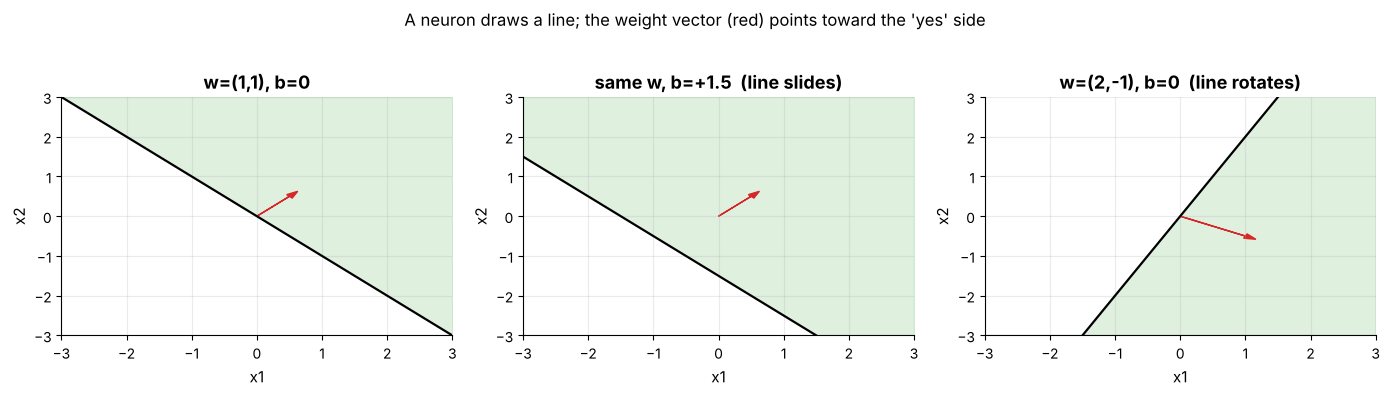

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
xs = np.linspace(-3, 3, 100)
for ax, (w1, w2, b_, title) in zip(axes, [(1, 1, 0, "w=(1,1), b=0"), (1, 1, 1.5, "same w, b=+1.5  (line slides)"), (2, -1, 0, "w=(2,-1), b=0  (line rotates)")]):
    ys = -(w1 * xs + b_) / w2
    ax.plot(xs, ys, "k"); ax.fill_between(xs, ys, 3 if w2 > 0 else -3, alpha=.15, color="tab:green")
    ax.set(xlim=(-3, 3), ylim=(-3, 3), title=title, xlabel="x1", ylabel="x2"); ax.arrow(0, 0, w1 * .5, w2 * .5, head_width=.12, color="tab:red")
plt.suptitle("A neuron draws a line; the weight vector (red) points toward the 'yes' side", y=1.03); plt.tight_layout(); plt.show()

---
### 🧩 Exercise 1: Compute a neuron by hand  ⭐

A neuron has weights `w = [0.4, -0.7, 1.2]`, bias `b = 0.1`, and inputs `x = [2.0, 1.0, 0.5]`.
Compute the pre-activation `z` and the **sigmoid** output `a_out` $=\frac{1}{1+e^{-z}}$.

<details><summary>💡 Hint 1: gentle nudge</summary>

`z = np.dot(w, x) + b`

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`np.exp(-z)` is $e^{-z}$.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`a_out = 1 / (1 + np.exp(-z))`

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
w = np.array([0.4, -0.7, 1.2]); b = 0.1; x = np.array([2.0, 1.0, 0.5])
z = None
a_out = None

In [ ]:
try:
    ag.check("z is right (0.8 - 0.7 + 0.6 + 0.1 = 0.8)", z is not None and np.isclose(z, 0.8))
    ag.check("sigmoid output is right", a_out is not None and np.isclose(a_out, 1 / (1 + np.exp(-0.8))))
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
## 2 · Activation functions: the "squash"

| Name | Formula | Range | Used for | Watch out |
|---|---|---|---|---|
| **Step** | $1$ if $z>0$ else $0$ | {0,1} | the original perceptron | no gradient → can't use gradient descent |
| **Sigmoid** | $\frac{1}{1+e^{-z}}$ | (0,1) | binary output probability | **saturates** (gradient → 0 for big |z|) |
| **Tanh** | $\frac{e^z-e^{-z}}{e^z+e^{-z}}$ | (−1,1) | recurrent nets | also saturates, but zero-centred |
| **ReLU** | $\max(0,z)$ | [0,∞) | **default for hidden layers** | "dying ReLU": neurons stuck at 0 |
| **Leaky ReLU** | $\max(\alpha z, z)$ | ℝ | fix for dying ReLU | extra hyper-parameter |
| **Softmax** | $\frac{e^{z_i}}{\sum_j e^{z_j}}$ | probs sum to 1 | multi-class output | use the **stable** version |

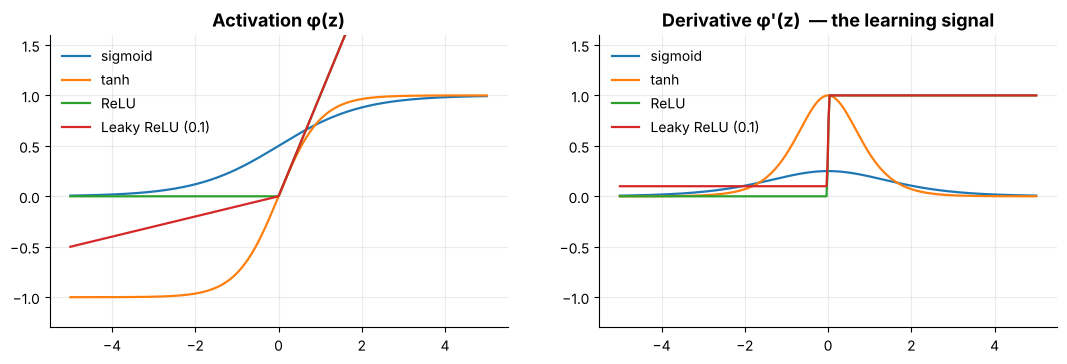

In [6]:
z = np.linspace(-5, 5, 400)
acts = {
    "sigmoid": 1 / (1 + np.exp(-z)),
    "tanh": np.tanh(z),
    "ReLU": np.maximum(0, z),
    "Leaky ReLU (0.1)": np.where(z > 0, z, 0.1 * z),
}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for name, a in acts.items():
    axes[0].plot(z, a, label=name); axes[1].plot(z, np.gradient(a, z), label=name)
axes[0].set_title("Activation φ(z)"); axes[1].set_title("Derivative φ'(z): the learning signal")
for ax in axes: ax.legend(); ax.set_ylim(-1.3, 1.6)
plt.show()

Look at the right panel: the **sigmoid's derivative is nearly zero** for $|z|>4$. During learning, gradients flow *through* derivatives: a saturated neuron barely learns
(**vanishing gradients**). ReLU's derivative is exactly 1 for positive inputs, which is why it dominates modern hidden layers.

---
### 🧩 Exercise 2: Write the activation functions  ⭐⭐

Implement NumPy functions `sigmoid(z)`, `tanh_(z)`, `relu(z)`, `leaky_relu(z, alpha=0.01)` and a **numerically stable** `softmax(z)` for a 1-D vector
(subtract the max before exponentiating so large inputs don't overflow).

<details><summary>💡 Hint 1: gentle nudge</summary>

`np.maximum(0, z)` is ReLU; `np.where(z > 0, z, alpha * z)` is Leaky ReLU.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`tanh_` can simply return `np.tanh(z)`, but try the formula `(e^z - e^-z)/(e^z + e^-z)` for practice.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

Stable softmax: `e = np.exp(z - np.max(z)); return e / e.sum()`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
def sigmoid(z): return None
def tanh_(z): return None
def relu(z): return None
def leaky_relu(z, alpha=0.01): return None
def softmax(z): return None

In [ ]:
try:
    t = np.array([-2., 0., 3.])
    ag.check("sigmoid", np.allclose(sigmoid(t), 1 / (1 + np.exp(-t))))
    ag.check("tanh", np.allclose(tanh_(t), np.tanh(t)))
    ag.check("relu", np.allclose(relu(t), [0, 0, 3]))
    ag.check("leaky relu", np.allclose(leaky_relu(t, 0.1), [-0.2, 0, 3]))
    s = softmax(np.array([1000., 1001., 1002.]))
    ag.check("softmax is stable and sums to 1", np.all(np.isfinite(s)) and np.isclose(s.sum(), 1) and s.argmax() == 2,
             "subtract the maximum first")
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
## 3 · The perceptron: a neuron that learns

Frank Rosenblatt (1958): show the neuron examples; whenever it is wrong, **nudge the weights toward the right answer**.

$$\hat y = \text{step}(\mathbf w\cdot\mathbf x + b), \qquad \mathbf w \leftarrow \mathbf w + \eta\,(y-\hat y)\,\mathbf x,\qquad b \leftarrow b + \eta\,(y-\hat y)$$

- If correct: $y-\hat y=0$ → no change.
- If it said 0 but should be 1: add $\eta\mathbf x$ → the weights tilt toward this input, raising $z$.
- If it said 1 but should be 0: subtract → lowers $z$.

**Perceptron convergence theorem:** if the classes are **linearly separable**, this rule finds a separating line in finitely many updates.

Dataset: our cooperative's historical "sell / hold" decisions (synthetic, 3 features: price z-score, rain forecast, storage cost).

samples: 181 | sell fraction: 0.35
learned w: [0.33 0.09 0.1 ] b: -0.2 | epochs needed: 3


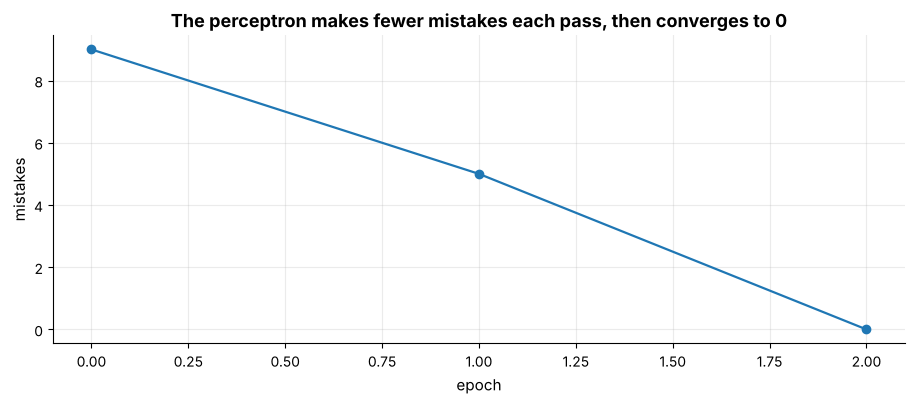

In [9]:
rng = np.random.default_rng(0)
X = np.column_stack([rng.normal(0, 1, 200), rng.uniform(0, 1, 200), rng.uniform(0, 1, 200)])
true_w, true_b = np.array([2.0, 0.5, 1.0]), -1.5
score = X @ true_w + true_b
keep = np.abs(score) > 0.3                           # leave a margin so the data are cleanly separable
X, y_sell = X[keep], (score[keep] > 0).astype(int)
print("samples:", len(X), "| sell fraction:", y_sell.mean().round(2))

def train_perceptron_demo(X, y, lr=0.1, epochs=50):
    w, b = np.zeros(X.shape[1]), 0.0
    errors = []
    for _ in range(epochs):
        n_err = 0
        for xi, yi in zip(X, y):
            yhat = 1 if xi @ w + b > 0 else 0
            upd = lr * (yi - yhat)
            w += upd * xi; b += upd; n_err += int(upd != 0)
        errors.append(n_err)
        if n_err == 0: break
    return w, b, errors

w_hat, b_hat, errs = train_perceptron_demo(X, y_sell)
print("learned w:", w_hat.round(2), "b:", round(b_hat, 2), "| epochs needed:", len(errs))
plt.plot(errs, marker="o"); plt.xlabel("epoch"); plt.ylabel("mistakes"); plt.title("The perceptron makes fewer mistakes each pass, then converges to 0"); plt.show()

---
### 🧩 Exercise 3: Train a perceptron on logic gates  ⭐⭐

Write `train_perceptron(X, y, lr=0.1, epochs=100)` returning `(w, b)`.
Train it on the **AND** and **OR** truth tables below and on **XOR**; store the final accuracies in `acc = {"AND": .., "OR": .., "XOR": ..}`.
Predictions use `step(X @ w + b > 0)`.

<details><summary>💡 Hint 1: gentle nudge</summary>

Initialise `w = np.zeros(X.shape[1])`, `b = 0.0`. Loop over epochs, and over samples inside.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

For each sample: `yhat = int(xi @ w + b > 0)`; `w += lr * (yi - yhat) * xi`; `b += lr * (yi - yhat)`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

Accuracy: `np.mean((X @ w + b > 0).astype(int) == y)`. XOR can never reach 1.0: that's the point of the next section.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
X_gate = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], float)
y_and, y_or, y_xor = np.array([0, 0, 0, 1]), np.array([0, 1, 1, 1]), np.array([0, 1, 1, 0])

def train_perceptron(X, y, lr=0.1, epochs=100):
    return None, None

acc = {}

In [ ]:
try:
    ag.check("AND is learned perfectly", acc.get("AND") == 1.0)
    ag.check("OR is learned perfectly", acc.get("OR") == 1.0)
    ag.check("XOR is NOT solved by a single perceptron (accuracy < 1)", acc.get("XOR", 1) < 1.0, "no single straight line separates XOR")
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
## 4 · The XOR crisis: and the way out

XOR is "true when exactly one input is on". Plot it and try to draw **one** straight line that separates the 1s from the 0s:

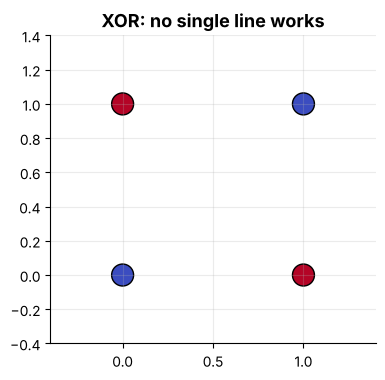

In [12]:
Xg = np.array([[0, 0], [0, 1], [1, 0], [1, 1]]); yx = np.array([0, 1, 1, 0])
plt.figure(figsize=(4.2, 4)); plt.scatter(Xg[:, 0], Xg[:, 1], c=yx, cmap="coolwarm", s=250, edgecolor="k")
plt.title("XOR: no single line works"); plt.xlim(-.4, 1.4); plt.ylim(-.4, 1.4); plt.show()

This 1969 observation (Minsky & Papert) triggered the first "AI winter". The escape: **stack neurons into layers**.
A hidden layer *transforms the space* so the problem *becomes* linearly separable:

- hidden neuron **h1 = OR(x1, x2)**, hidden neuron **h2 = AND(x1, x2)**
- output = **h1 AND NOT h2** → "at least one, but not both" = XOR.

The three kinds of layer in a feed-forward network:

| Layer | Role |
|---|---|
| **Input** | just the data (no computation) |
| **Hidden** | learned intermediate features |
| **Output** | the prediction (sigmoid for binary, softmax for classes, none for regression) |

A layer of neurons is one **matrix multiply**: $\mathbf a = \varphi(W\mathbf x + \mathbf b)$ with $W$ of shape (neurons × inputs).

In [13]:
step = lambda z: (z > 0).astype(int)
W1 = np.array([[1, 1],      # h1 = OR : x1 + x2 - 0.5 > 0
               [1, 1]])     # h2 = AND: x1 + x2 - 1.5 > 0
b1 = np.array([-0.5, -1.5])
W2 = np.array([[1, -1]]);  b2 = np.array([-0.5])      # out = h1 AND NOT h2

H = step(Xg @ W1.T + b1)
out = step(H @ W2.T + b2).ravel()
print("hidden activations (h1=OR, h2=AND):\n", H, "\nnetwork output:", out, "| XOR truth:", yx)

hidden activations (h1=OR, h2=AND):


 [[0 0]
 [1 0]
 [1 0]
 [1 1]] 
network output: [0 1 1 0] | XOR truth: [0 1 1 0]


---
### 🧩 Exercise 4: Design your own XOR network  ⭐⭐⭐

Using the structure above, find *different* weights that also solve XOR with **step** activations:
make hidden neuron 1 compute **NAND** and hidden neuron 2 compute **OR**, and the output compute **AND** of the two hidden neurons.
Fill `W1` (2×2), `b1` (2), `W2` (1×2), `b2` (1) so that the network output equals XOR on all four inputs.

<details><summary>💡 Hint 1: gentle nudge</summary>

NAND: `-x1 - x2 + 1.5 > 0`  (weights −1, −1; bias 1.5). OR: `x1 + x2 - 0.5 > 0`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

Rows of `W1` are neurons: `W1 = [[-1, -1], [1, 1]]`, `b1 = [1.5, -0.5]`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

AND of two binary hidden units: `W2 = [[1, 1]]`, `b2 = [-1.5]`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
W1 = np.zeros((2, 2)); b1 = np.zeros(2)
W2 = np.zeros((1, 2)); b2 = np.zeros(1)

In [ ]:
try:
    pred = step(step(Xg @ W1.T + b1) @ W2.T + b2).ravel()
    ag.check("network reproduces XOR on all 4 inputs", np.array_equal(pred, yx), "hidden: NAND and OR; output: AND")
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
## 5 · Why activations matter, and how to count parameters

**Without an activation, depth is an illusion.** Two linear layers: $W_2(W_1\mathbf x) = (W_2W_1)\mathbf x$: just *one* linear layer. Let's verify numerically.

In [16]:
rng = np.random.default_rng(1)
W1_, W2_, x_ = rng.normal(size=(5, 3)), rng.normal(size=(2, 5)), rng.normal(size=3)
print("two linear layers :", (W2_ @ (W1_ @ x_)).round(4))
print("one merged layer  :", ((W2_ @ W1_) @ x_).round(4), "  <- identical: depth added nothing")
print("with ReLU between :", (W2_ @ np.maximum(0, W1_ @ x_)).round(4), "  <- genuinely different function")

two linear layers : [-0.497 -4.806]
one merged layer  : [-0.497 -4.806]   <- identical: depth added nothing
with ReLU between : [-0.5554 -4.0017]   <- genuinely different function


**Counting parameters.** A dense layer from $n_\text{in}$ to $n_\text{out}$ neurons has $n_\text{in}\times n_\text{out}$ weights plus $n_\text{out}$ biases.
This number controls memory, compute, and the risk of overfitting.

---
### 🧩 Exercise 5: How many parameters?  ⭐

A digit-recognition MLP has layer sizes `[784, 128, 64, 10]` (input → hidden → hidden → output).
Write `count_params(sizes)` and compute `n_params`. Also store the per-layer counts in a list `per_layer`.

<details><summary>💡 Hint 1: gentle nudge</summary>

For each consecutive pair `(n_in, n_out)` in `zip(sizes[:-1], sizes[1:])`: `n_in * n_out + n_out`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

Sum the list for the total.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

Layer 1: 784·128 + 128 = 100,480.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
def count_params(sizes):
    return [], None

per_layer, n_params = count_params([784, 128, 64, 10])

In [ ]:
try:
    ag.check("per-layer counts", per_layer == [100480, 8256, 650])
    ag.check("total is 109,386", n_params == 109386)
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

## 🎓 Mini-quiz
1. What happens to a perceptron's weights when it classifies an example correctly?
2. Why can't a single neuron learn XOR, and what's the smallest fix?
3. Which activation would you use for (a) hidden layers, (b) a 10-class output, (c) a price regression output?

<details><summary>Answers</summary>

1. Nothing: the update is proportional to the error, which is zero.
2. XOR is not linearly separable; a neuron draws one line. Add a hidden layer (two hidden neurons suffice).
3. (a) ReLU (b) softmax (c) none / identity.
</details>

        ---
        ## 🧾 Recap
        - A neuron = **weighted sum + bias, then an activation**. Weights set importance; bias shifts the threshold; the activation adds non-linearity.
- A single neuron draws one line (hyperplane). The perceptron rule learns it **if** the data are linearly separable.
- **Hidden layers** make XOR-like problems solvable; layers are matrix multiplications; without activations depth collapses.
- ReLU for hidden layers, sigmoid/softmax for probabilities; count parameters as $n_\text{in}n_\text{out}+n_\text{out}$.

**Next up:** Lesson 8.2: how a network *learns*: loss functions, gradient descent, forward propagation and back-propagation, coded from scratch.